# 03c. Classical Supervised Model Benchmark & Imbalance Study

Compares classical models (`LogReg`, `Perceptron`, `GaussianNB`, `DecisionTree`, `SVM_RBF`, `RandomForest`, `HistGB`) across unweighted, class-weighted, and oversampled regimes using 5-fold patient-grouped CV and held-out test evaluation.

## 1. Imports & Load Splits

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [ ]:

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "src-code" else cwd


SEED = 42
N_FOLDS = 5
SAVE = True
DATA_DIR = Path("../Dataset/modelling")
OUT_DIR = PROJECT_ROOT / "Output" / "04_supervised_eval"
if SAVE:
    OUT_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "final_train.csv")
test_df = pd.read_csv(DATA_DIR / "final_test.csv")
with open(DATA_DIR / "feature_metadata.json") as f:
    meta = json.load(f)

feature_cols = meta["feature_cols"]
LABELS = meta["labels"]
MEL_IDX = LABELS.index("MEL")
MALIGNANT_IDXS = [LABELS.index(c) for c in ["BCC", "SCC", "MEL"]]

X_train = train_df[feature_cols]
y_train = train_df["y_multiclass"].values
g_train = train_df["patient_id"].fillna(pd.Series(train_df.index.astype(str))).values

X_test = test_df[feature_cols]
y_test = test_df["y_multiclass"].values

## 2. Define Classical Models & Imbalance Pipelines

In [2]:
models = {
    "LogReg_Weighted": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    ]),
    "LogReg_Unweighted": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
    "Perceptron_Weighted": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", Perceptron(max_iter=1000, class_weight="balanced", random_state=SEED)),
    ]),
    "GaussianNB": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", GaussianNB()),
    ]),
    "DecisionTree_Weighted": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, class_weight="balanced", random_state=SEED)),
    ]),
    "SVM_RBF_Weighted": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=1.0, class_weight="balanced", probability=True, random_state=SEED)),
    ]),
    "RandomForest_Weighted": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_leaf=3,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED
        )),
    ]),
    "RandomForest_ROS": ImbPipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("ros", RandomOverSampler(random_state=SEED)),
        ("clf", RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_leaf=3,
            n_jobs=-1, random_state=SEED
        )),
    ]),
    "HistGB_Default": Pipeline([
        ("clf", HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.05, max_leaf_nodes=31,
            min_samples_leaf=10, random_state=SEED
        )),
    ]),
    "HistGB_Weighted": Pipeline([
        ("clf", HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.05, max_leaf_nodes=31,
            min_samples_leaf=10, class_weight="balanced", random_state=SEED
        )),
    ]),
}
print("Models configured:", list(models.keys()))

Models configured: ['LogReg_Weighted', 'LogReg_Unweighted', 'Perceptron_Weighted', 'GaussianNB', 'DecisionTree_Weighted', 'SVM_RBF_Weighted', 'RandomForest_Weighted', 'RandomForest_ROS', 'HistGB_Default', 'HistGB_Weighted']


## 3. 5-Fold Patient-Grouped Cross-Validation

=== 5-Fold Patient-Grouped CV Results ===
                model  cv_f1_macro_mean  cv_f1_macro_std  cv_bal_acc_mean  cv_acc_mean  cv_mel_recall_mean
    LogReg_Unweighted            0.6163           0.0341           0.6224       0.7521              0.4689
      LogReg_Weighted            0.6104           0.0200           0.6538       0.6915              0.5589
RandomForest_Weighted            0.6080           0.0371           0.6240       0.7135              0.6244
     RandomForest_ROS            0.6019           0.0393           0.6081       0.7040              0.5144
      HistGB_Weighted            0.5971           0.0474           0.5925       0.7228              0.3967
     SVM_RBF_Weighted            0.5941           0.0419           0.5980       0.6676              0.4800
       HistGB_Default            0.5747           0.0397           0.5633       0.7209              0.3078
  Perceptron_Weighted            0.5527           0.0324           0.5980       0.6424              0.

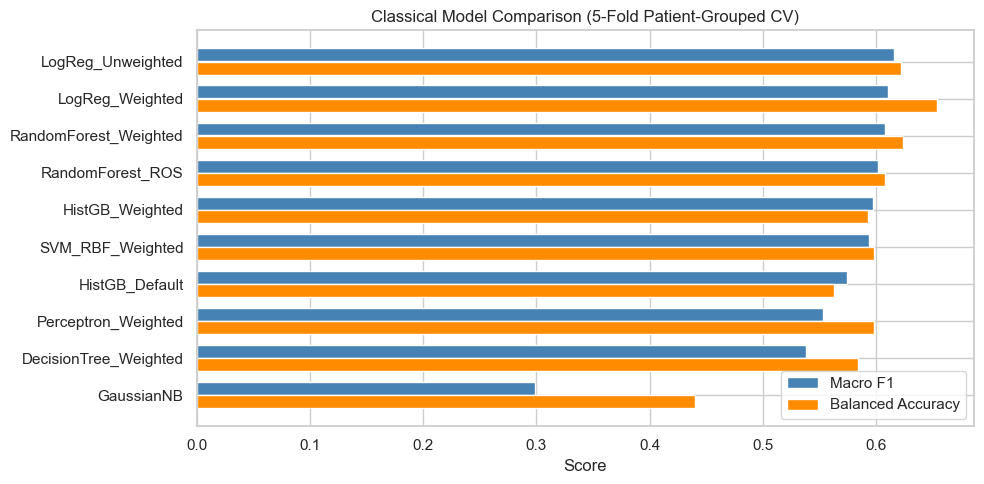

In [3]:
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_records = []

for name, pipe in models.items():
    f1_macros, bal_accs, accs, mel_recalls = [], [], [], []
    for tr_idx, va_idx in cv.split(X_train, y_train, g_train):
        pipe.fit(X_train.iloc[tr_idx], y_train[tr_idx])
        preds = pipe.predict(X_train.iloc[va_idx])
        present = np.unique(y_train[va_idx])

        f1_macros.append(f1_score(y_train[va_idx], preds, labels=present, average="macro", zero_division=0))
        bal_accs.append(balanced_accuracy_score(y_train[va_idx], preds))
        accs.append(accuracy_score(y_train[va_idx], preds))

        if MEL_IDX in present:
            mel_mask = y_train[va_idx] == MEL_IDX
            mel_recalls.append((preds[mel_mask] == MEL_IDX).mean())

    cv_records.append({
        "model": name,
        "cv_f1_macro_mean": np.mean(f1_macros),
        "cv_f1_macro_std": np.std(f1_macros),
        "cv_bal_acc_mean": np.mean(bal_accs),
        "cv_acc_mean": np.mean(accs),
        "cv_mel_recall_mean": np.mean(mel_recalls) if mel_recalls else np.nan,
    })

cv_df = pd.DataFrame(cv_records).sort_values("cv_f1_macro_mean", ascending=False)
print("=== 5-Fold Patient-Grouped CV Results ===")
print(cv_df.round(4).to_string(index=False))
if SAVE:
    cv_df.to_csv(OUT_DIR / "cv_model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(cv_df))
ax.barh(y_pos - 0.18, cv_df["cv_f1_macro_mean"], height=0.35, label="Macro F1", color="steelblue")
ax.barh(y_pos + 0.18, cv_df["cv_bal_acc_mean"], height=0.35, label="Balanced Accuracy", color="darkorange")
ax.set_yticks(y_pos)
ax.set_yticklabels(cv_df["model"])
ax.invert_yaxis()
ax.set_xlabel("Score")
ax.set_title("Classical Model Comparison (5-Fold Patient-Grouped CV)")
ax.legend()
plt.tight_layout()
if SAVE:
    fig.savefig(OUT_DIR / "cv_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Hold-Out Test Set Evaluation

In [4]:
test_records = []
fitted_models = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    preds = pipe.predict(X_test)

    ovr_auc = (
        roc_auc_score(y_test, pipe.predict_proba(X_test), multi_class="ovr", average="macro")
        if hasattr(pipe, "predict_proba") else np.nan
    )
    mel_mask = y_test == MEL_IDX
    true_mal = np.isin(y_test, MALIGNANT_IDXS)
    pred_mal = np.isin(preds, MALIGNANT_IDXS)

    test_records.append({
        "model": name,
        "test_f1_macro": f1_score(y_test, preds, average="macro", zero_division=0),
        "test_bal_acc": balanced_accuracy_score(y_test, preds),
        "test_acc": accuracy_score(y_test, preds),
        "test_roc_auc_ovr": ovr_auc,
        "test_mel_recall": (preds[mel_mask] == MEL_IDX).mean(),
        "test_malignant_recall": pred_mal[true_mal].mean(),
    })

test_df_res = pd.DataFrame(test_records).sort_values("test_f1_macro", ascending=False)
print("=== Hold-Out Test Set Results ===")
print(test_df_res.round(4).to_string(index=False))
if SAVE:
    test_df_res.to_csv(OUT_DIR / "test_model_comparison.csv", index=False)

=== Hold-Out Test Set Results ===
                model  test_f1_macro  test_bal_acc  test_acc  test_roc_auc_ovr  test_mel_recall  test_malignant_recall
    LogReg_Unweighted         0.6253        0.6430    0.7665            0.9292            0.500                 0.9217
     SVM_RBF_Weighted         0.6209        0.6497    0.7452            0.9294            0.375                 0.9447
      LogReg_Weighted         0.6066        0.6811    0.6943            0.9269            0.625                 0.9032
     RandomForest_ROS         0.6012        0.6287    0.7410            0.9311            0.500                 0.9724
RandomForest_Weighted         0.5981        0.6307    0.7367            0.9274            0.500                 0.9724
      HistGB_Weighted         0.5872        0.5909    0.7452            0.9121            0.375                 0.9447
       HistGB_Default         0.5657        0.5699    0.7346            0.9157            0.375                 0.9493
  Perceptron_W

## 5. Best Model Confusion Matrix, Feature Importance & Error Analysis

=== Classification Report: LogReg_Unweighted (Test Set) ===
              precision    recall  f1-score   support

         NEV     0.8462    0.8148    0.8302        54
         ACK     0.8282    0.8438    0.8359       160
         SEK     0.7568    0.7000    0.7273        40
         BCC     0.7912    0.8229    0.8067       175
         SCC     0.2857    0.1765    0.2182        34
         MEL     0.2500    0.5000    0.3333         8

    accuracy                         0.7665       471
   macro avg     0.6263    0.6430    0.6253       471
weighted avg     0.7615    0.7665    0.7621       471



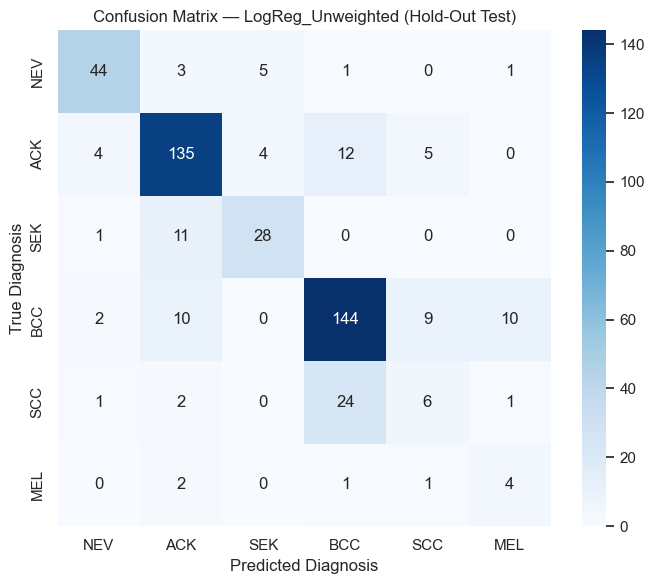


=== Top 15 Features (RandomForest_Weighted) ===
           feature  importance
               age      0.1018
    age_x_symptoms      0.0727
symptom_per_decade      0.0658
         itch_true      0.0583
      changed_true      0.0447
    elevation_true      0.0443
           biopsed      0.0401
     symptom_count      0.0320
          log_area      0.0292
    diameter_ratio      0.0270
         grew_true      0.0244
     mean_diameter      0.0240
        bleed_true      0.0230
        diameter_2      0.0205
        diameter_1      0.0205


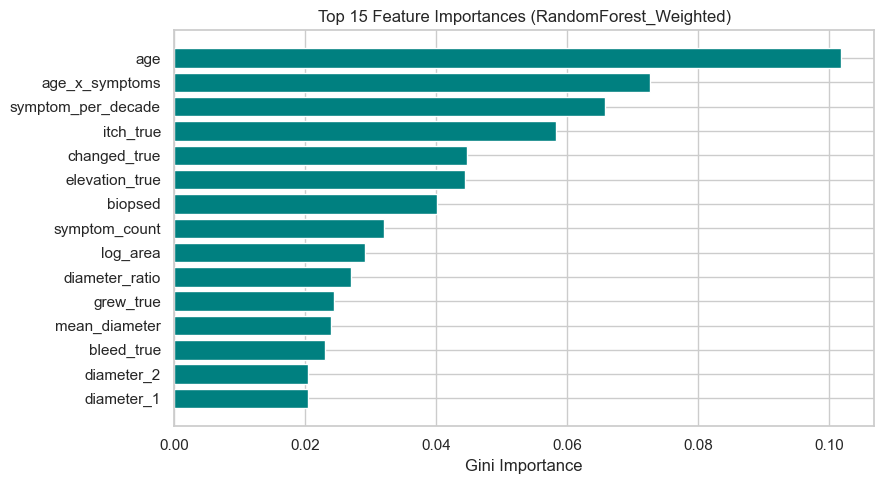


=== Malignant False Negatives (LogReg_Unweighted) ===
Total malignant in test: 217 | Missed as benign: 17
diagnostic pred_label  count
       BCC        ACK     10
       BCC        NEV      2
       MEL        ACK      2
       SCC        ACK      2
       SCC        NEV      1


In [5]:
best_model_name = cv_df.iloc[0]["model"]
best_pipe = fitted_models[best_model_name]
best_preds = best_pipe.predict(X_test)

print(f"=== Classification Report: {best_model_name} (Test Set) ===")
print(classification_report(y_test, best_preds, target_names=LABELS, digits=4, zero_division=0))

cm = confusion_matrix(y_test, best_preds)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax)
ax.set_title(f"Confusion Matrix — {best_model_name} (Hold-Out Test)")
ax.set_xlabel("Predicted Diagnosis")
ax.set_ylabel("True Diagnosis")
plt.tight_layout()
if SAVE:
    fig.savefig(OUT_DIR / "best_model_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Feature importances from RandomForest_Weighted
rf_pipe = fitted_models["RandomForest_Weighted"]
importances = rf_pipe.named_steps["clf"].feature_importances_
fi_df = pd.DataFrame({"feature": feature_cols, "importance": importances}).sort_values("importance", ascending=False)
print("\n=== Top 15 Features (RandomForest_Weighted) ===")
print(fi_df.head(15).round(4).to_string(index=False))
if SAVE:
    fi_df.to_csv(OUT_DIR / "rf_feature_importances.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
top15 = fi_df.head(15)
ax.barh(top15["feature"][::-1], top15["importance"][::-1], color="teal")
ax.set_title("Top 15 Feature Importances (RandomForest_Weighted)")
ax.set_xlabel("Gini Importance")
plt.tight_layout()
if SAVE:
    fig.savefig(OUT_DIR / "rf_top15_features.png", dpi=300, bbox_inches="tight")
plt.show()

# Malignant false negatives
err_df = test_df.copy()
err_df["pred_label"] = [LABELS[i] for i in best_preds]
err_df["is_malignant_fn"] = (err_df["is_cancer"] == 1) & (~err_df["pred_label"].isin(["BCC", "SCC", "MEL"]))
fn_summary = err_df[err_df["is_malignant_fn"]].groupby(["diagnostic", "pred_label"]).size().rename("count").reset_index()

print(f"\n=== Malignant False Negatives ({best_model_name}) ===")
print(f"Total malignant in test: {err_df['is_cancer'].sum()} | Missed as benign: {err_df['is_malignant_fn'].sum()}")
print(fn_summary.to_string(index=False))
if SAVE:
    err_df[err_df["is_malignant_fn"]].to_csv(OUT_DIR / "malignant_false_negatives.csv", index=False)